In [21]:
import pandas as pd
import re
from google.colab import files

print("Please upload your mail_data.csv file:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Load and clean
df = pd.read_csv(filename)
df = df.dropna(subset=['Message']).reset_index(drop=True)
df['label'] = df['Category'].map({'ham': 0, 'spam': 1})

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' url ', text)
    text = re.sub(r'\d+', ' num ', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_msg'] = df['Message'].apply(clean_text)
print("Step 1 Complete: Data loaded and cleaned!")

Please upload your mail_data.csv file:


Saving mail_data.csv to mail_data (2).csv
Step 1 Complete: Data loaded and cleaned!


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

print("2. Splitting data and converting text to numbers...")

# Split 80% train, 20% test
X = df['clean_msg']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Convert text to numbers (TF-IDF)
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("\nStep 2 Complete: Data split and vectorized!")
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

2. Splitting data and converting text to numbers...

Step 2 Complete: Data split and vectorized!
Training messages: 4457
Testing messages: 1115


In [26]:
from sklearn.svm import LinearSVC
import time

print("Training Linear SVM...")
start_time = time.time()

# 1. Create the model
svm_model = LinearSVC(random_state=42)

# 2. Train the model (this is where it learns from the data)
svm_model.fit(X_train_vec, y_train)

end_time = time.time()
print(f"Linear SVM trained successfully in {end_time - start_time:.2f} seconds!")

Training Linear SVM...
Linear SVM trained successfully in 0.02 seconds!


In [27]:
from sklearn.linear_model import LogisticRegression
import time

print("Training Logistic Regression...")
start_time = time.time()

# 1. Create the model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# 2. Train the model
lr_model.fit(X_train_vec, y_train)

end_time = time.time()
print(f"Logistic Regression trained successfully in {end_time - start_time:.2f} seconds!")

Training Logistic Regression...
Logistic Regression trained successfully in 0.07 seconds!


In [28]:
from sklearn.ensemble import RandomForestClassifier
import time

print("Training Random Forest...")
start_time = time.time()

# 1. Create the model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Train the model
rf_model.fit(X_train_vec, y_train)

end_time = time.time()
print(f"Random Forest trained successfully in {end_time - start_time:.2f} seconds!")

Training Random Forest...
Random Forest trained successfully in 2.34 seconds!


In [29]:
from xgboost import XGBClassifier
import time
import warnings

# Ignore warnings for clean output
warnings.filterwarnings("ignore")

print("Training XGBoost...")
start_time = time.time()

# 1. Create the model
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

# 2. Train the model
xgb_model.fit(X_train_vec, y_train)

end_time = time.time()
print(f"XGBoost trained successfully in {end_time - start_time:.2f} seconds!")

Training XGBoost...
XGBoost trained successfully in 3.77 seconds!


In [33]:
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings("ignore")

print("Training XGBoost...")
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train_vec, y_train)
print("XGBoost trained successfully!")

Training XGBoost...
XGBoost trained successfully!


In [35]:
import time
import warnings
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Ignore warnings for clean output
warnings.filterwarnings("ignore")

print("Training and testing all 5 models... (This takes about 2 seconds)\n")

# 1. Define all 5 models in one dictionary
models = {
    "Linear SVM": LinearSVC(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

print("=" * 85)
print("MODEL EVALUATION AND COMPARISON")
print("=" * 85)
print(f"{'Model':<22}{'Accuracy':<12}{'Precision':<12}{'Recall':<10}{'F1':<10}")
print("-" * 85)

results = []
best_f1 = 0
best_model = None
best_preds = None
best_name = ""

# 2. Train, test, and evaluate each model
for name, m in models.items():
    # Train
    m.fit(X_train_vec, y_train)

    # Predict
    preds = m.predict(X_test_vec)

    # Evaluate
    acc  = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec  = recall_score(y_test, preds)
    f1   = f1_score(y_test, preds)

    # Store results
    results.append({"name": name, "f1": f1})

    # Find the winner
    if f1 > best_f1:
        best_f1 = f1
        best_model = m
        best_preds = preds
        best_name = name

    print(f"{name:<22}{acc*100:>6.2f}%     {prec:>6.2f}      {rec:>6.2f}    {f1:>6.2f}")

print("-" * 85)
print(f"\nTHE WINNER IS: {best_name} (F1 Score: {best_f1:.4f})")

Training and testing all 5 models... (This takes about 2 seconds)

MODEL EVALUATION AND COMPARISON
Model                 Accuracy    Precision   Recall    F1        
-------------------------------------------------------------------------------------
Linear SVM             98.92%       0.97        0.95      0.96
Logistic Regression    97.31%       0.95        0.85      0.89
Naive Bayes            97.67%       1.00        0.83      0.90
Random Forest          98.03%       1.00        0.85      0.92
XGBoost                97.04%       0.91        0.86      0.89
-------------------------------------------------------------------------------------

THE WINNER IS: Linear SVM (F1 Score: 0.9592)


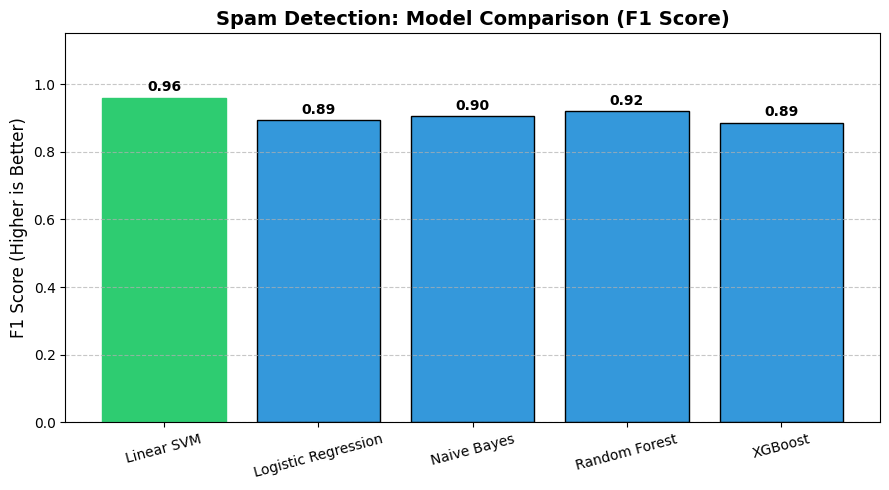

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ==========================================
# CHART 1: F1 Score Comparison Bar Chart
# ==========================================
names = [r['name'] for r in results]
scores = [r['f1'] for r in results]

plt.figure(figsize=(9, 5))
bars = plt.bar(names, scores, color='#3498db', edgecolor='black')

# Highlight the winner in green
for i, bar in enumerate(bars):
    if names[i] == best_name:
        bar.set_color('#2ecc71')

    # Add the score number on top of each bar
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.2f}",
             ha='center', va='bottom', fontweight='bold')

plt.title('Spam Detection: Model Comparison (F1 Score)', fontsize=14, fontweight='bold')
plt.ylabel('F1 Score (Higher is Better)', fontsize=12)
plt.ylim(0, 1.15)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ==========================================
# CHART 2: Confusion Matrix for the Winner
# ==========================================


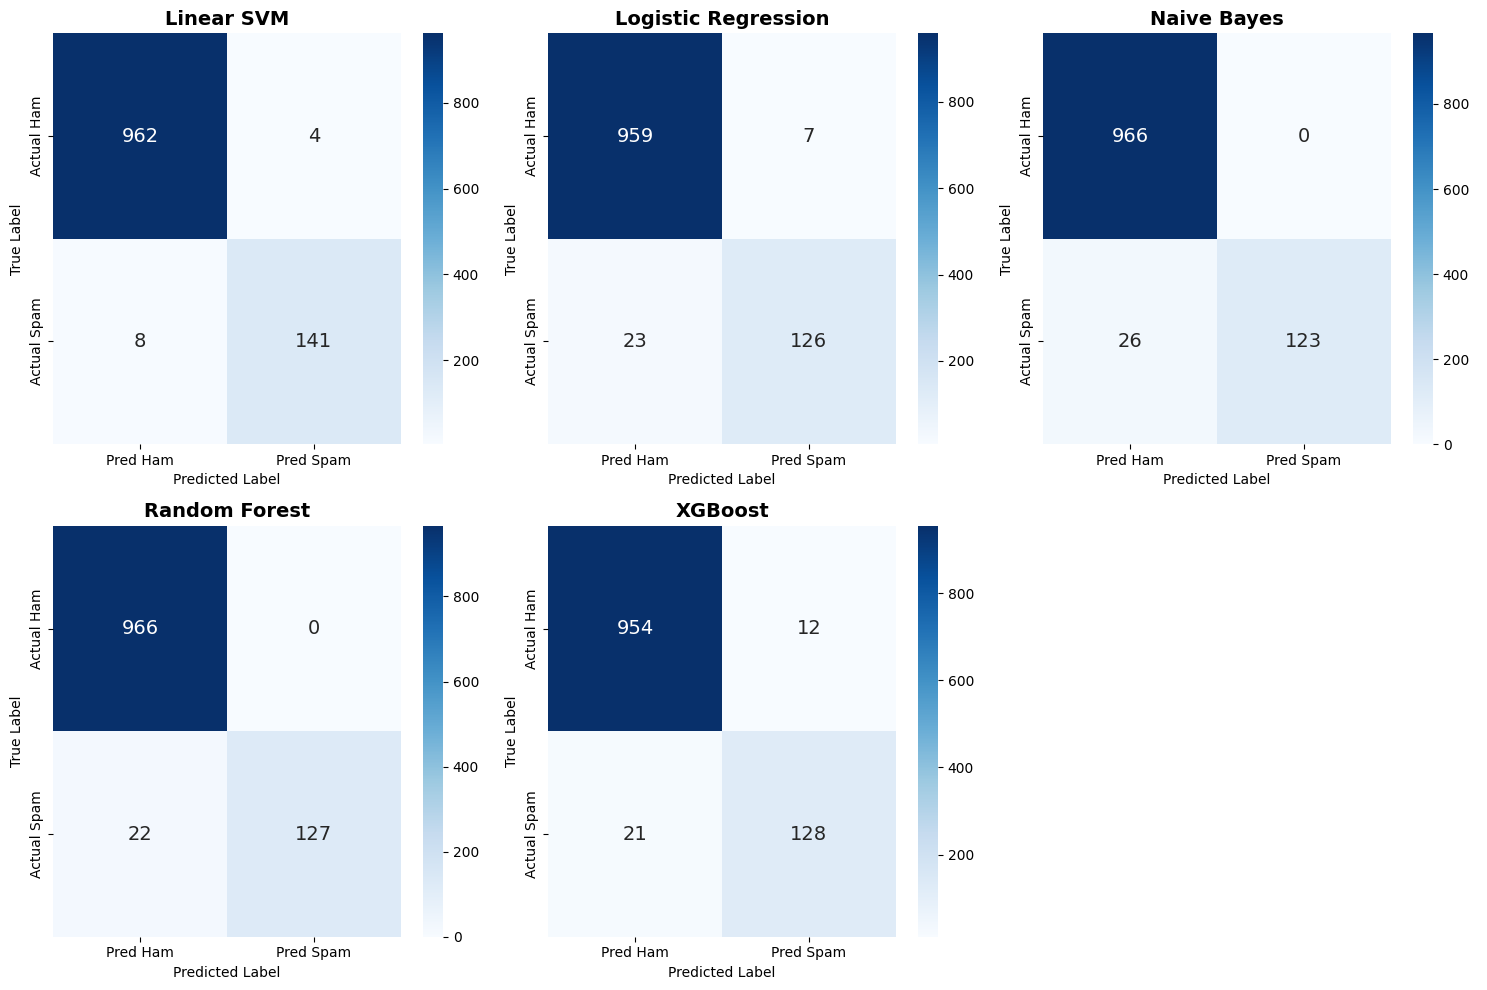

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# We will loop through all 5 models to generate a matrix for each
model_names = ["Linear SVM", "Logistic Regression", "Naive Bayes", "Random Forest", "XGBoost"]

# Set up a 2x3 grid for the plots (5 plots + 1 empty space)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, name in enumerate(model_names):
    # Get the model from our dictionary
    model = models[name]

    # Make predictions
    preds = model.predict(X_test_vec)

    # Create Confusion Matrix
    cm = confusion_matrix(y_test, preds)

    # Draw the heatmap in the specific subplot
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Pred Ham', 'Pred Spam'],
                yticklabels=['Actual Ham', 'Actual Spam'],
                annot_kws={"size": 14})

    axes[i].set_title(f'{name}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('True Label')
    axes[i].set_xlabel('Predicted Label')

# Hide the empty 6th subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

In [39]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create the UI elements
text_input = widgets.Text(
    placeholder='Type your message here...',
    description='Message:',
    layout=widgets.Layout(width='70%')
)

check_button = widgets.Button(
    description='Check Message',
    button_style='primary'
)

output_area = widgets.Output()

# Function to run when the button is clicked
def on_button_clicked(b):
    with output_area:
        clear_output()
        msg = text_input.value
        if not msg.strip():
            print("Please type a message first.")
            return

        # Call the predictor
        result = predict_spam(msg)

        # Print the result with colors
        if result == "SPAM":
            print(f"Result: \033[1;31m{result}\033[0m (This looks like spam!)")
        else:
            print(f"Result: \033[1;32m{result}\033[0m (This looks safe.)")

# Link the button to the function
check_button.on_click(on_button_clicked)

# Display the UI
print("=" * 50)
print("TEST THE SPAM DETECTOR")
print("=" * 50)
display(text_input, check_button, output_area)

TEST THE SPAM DETECTOR


Text(value='', description='Message:', layout=Layout(width='70%'), placeholder='Type your message here...')

Button(button_style='primary', description='Check Message', style=ButtonStyle())

Output()